In [12]:
#buat import semua library yang bakal dipake
#numpy buat operasi matematika, pandas buat olah data tabel,
#matplotlib buat visualisasi, sklearn buat evaluasi clustering,
#dan st_dbscan buat algoritma utama ST-DBSCAN

#install library st-dbscan dulu soalnya gak ada secara default di colab
!pip install st-dbscan --quiet

#import library-library utama yang dipakai sepanjang notebook ini
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import matplotlib.cm as cm
import warnings
warnings.filterwarnings('ignore')

#import algoritma ST-DBSCAN dan fungsi evaluasi clustering (silhouette)
from st_dbscan import ST_DBSCAN
from sklearn.metrics import silhouette_score, silhouette_samples

print("Library siap!")

Library siap!


In [13]:
#buat konek Google Drive ke Colab biar bisa akses file dataset gempa yang ada di Drive
from google.colab import drive
drive.mount('/drive')

Drive already mounted at /drive; to attempt to forcibly remount, call drive.mount("/drive", force_remount=True).


In [14]:
#buat load dataset katalog gempa bumi BMKG 2021-2023 dari Google Drive ke variabel df
df = pd.read_csv('/drive/MyDrive/gempa_2021_2023.csv')

#cek jumlah baris totalnya berapa, sekalian liat 3 baris pertama buat preview datanya
print(f"Total rows: {len(df)}")
print(df.head(3))

Total rows: 31615
   No     Event ID                         Date time  Latitude   Longitude  \
0   1  bmg2021aaat  2021-01-01 00:22:54.920667+00:00 -8.214952  117.809219   
1   2  bmg2021aabb  2021-01-01 00:33:29.697003+00:00 -9.013550  118.489365   
2   3  bmg2021aafc  2021-01-01 02:33:53.821278+00:00 -1.848494  120.531387   

   Magnitude Mag Type  Depth (km)  Phase Count  Azimuth Gap  \
0   3.483098        M          19           23   112.881405   
1   4.275109        M          67           51   152.755386   
2   3.920442        M          10           31    51.862602   

                    Location Agency  
0  Sumbawa Region, Indonesia   BMKG  
1  Sumbawa Region, Indonesia   BMKG  
2        Sulawesi, Indonesia   BMKG  


In [15]:
#buat ngecek informasi umum dataset, kayak jumlah baris, nama kolom, tipe data, sama berapa nilai yang kosong
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 31615 entries, 0 to 31614
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   No           31615 non-null  int64  
 1   Event ID     31615 non-null  object 
 2   Date time    31615 non-null  object 
 3   Latitude     31615 non-null  float64
 4   Longitude    31615 non-null  float64
 5   Magnitude    31615 non-null  float64
 6   Mag Type     31615 non-null  object 
 7   Depth (km)   31615 non-null  int64  
 8   Phase Count  31615 non-null  int64  
 9   Azimuth Gap  31615 non-null  float64
 10  Location     31608 non-null  object 
 11  Agency       31615 non-null  object 
dtypes: float64(4), int64(3), object(5)
memory usage: 2.9+ MB


In [16]:
#buat ngecek jumlah nilai kosong di tiap kolom dan persentasenya dari total jumlah baris
missing = df.isna().sum()
missing_pct = df.isna().sum() / len(df) * 100

#tampilin dalam bentuk tabel biar gampang dibaca
print(pd.DataFrame({'Missing': missing, 'Persen (%)': missing_pct.round(2)}))

             Missing  Persen (%)
No                 0        0.00
Event ID           0        0.00
Date time          0        0.00
Latitude           0        0.00
Longitude          0        0.00
Magnitude          0        0.00
Mag Type           0        0.00
Depth (km)         0        0.00
Phase Count        0        0.00
Azimuth Gap        0        0.00
Location           7        0.02
Agency             0        0.00


In [17]:
#buat ngecek jumlah data duplikat di dataset
duplicated = df.duplicated().sum()
print(f"Jumlah data duplikat: {duplicated}")

Jumlah data duplikat: 0


In [18]:
#buat pra-pemrosesan data: pilih kolom yang dibutuhkan, konversi datetime,
#dan buat kolom Time_days sebagai representasi numerik waktu dalam satuan hari

#ambil cuma kolom-kolom yang relevan buat clustering spatio-temporal
df_clean = df[['Date time', 'Latitude', 'Longitude', 'Magnitude', 'Depth (km)']].copy()

#konversi kolom Date time jadi format datetime asli (bukan string lagi)
df_clean['Date time'] = pd.to_datetime(df_clean['Date time'], utc=True)

#bikin kolom Time_days = selisih waktu tiap kejadian dari titik waktu paling awal,
#dihitung dalam satuan hari, soalnya ST-DBSCAN/ST-OPTICS butuh fitur waktu numerik
df_clean['Time_days'] = (df_clean['Date time'] - df_clean['Date time'].min()).dt.total_seconds() / 86400

#cek hasil akhirnya, shape dan preview 3 baris pertama
print(f"Shape: {df_clean.shape}")
print(df_clean.head(3))

Shape: (31615, 6)
                         Date time  Latitude   Longitude  Magnitude  \
0 2021-01-01 00:22:54.920667+00:00 -8.214952  117.809219   3.483098   
1 2021-01-01 00:33:29.697003+00:00 -9.013550  118.489365   4.275109   
2 2021-01-01 02:33:53.821278+00:00 -1.848494  120.531387   3.920442   

   Depth (km)  Time_days  
0          19   0.000000  
1          67   0.007347  
2          10   0.090959  


In [19]:
#buat sampling 2000 data secara acak untuk proses tuning parameter,
#lalu memisahkan fitur spasial (Latitude, Longitude) dan temporal (Time_days)

#ambil 2000 baris secara random (random_state=42 biar hasilnya konsisten/reproducible)
df_sample = df_clean.sample(n=2000, random_state=42).reset_index(drop=True)

#pisahin fitur spasial (lat, lon) dan fitur temporal (time_days) jadi dua array beda
#karena ST-DBSCAN butuh keduanya dipisah sebelum digabung lagi pas fit
X_spatial = df_sample[['Latitude', 'Longitude']].values
X_temporal = df_sample[['Time_days']].values

#cek shape masing-masing buat mastiin jumlah barisnya sama (2000)
print(f"Shape spatial: {X_spatial.shape}")
print(f"Shape temporal: {X_temporal.shape}")
print("Siap untuk ST-DBSCAN!")

Shape spatial: (2000, 2)
Shape temporal: (2000, 1)
Siap untuk ST-DBSCAN!


In [20]:
#buat mencari parameter optimal ST-DBSCAN menggunakan grid search
#dengan kombinasi eps1 (jarak spasial), eps2 (jarak temporal), dan min_samples,
#lalu mengevaluasi tiap kombinasi menggunakan Silhouette Score

#daftar nilai yang mau dicoba untuk masing-masing parameter ST-DBSCAN
eps1_list = [0.5, 1.0, 1.5]         # jarak spasial
eps2_list = [7, 14, 30]              # jarak temporal (hari)
min_samples_list = [3, 5, 10]        # minimum anggota cluster

#list buat nyimpen hasil tiap kombinasi parameter
results = []

#looping semua kombinasi eps1, eps2, min_samples (3x3x3 = 27 kombinasi)
for eps1 in eps1_list:
    for eps2 in eps2_list:
        for min_samples in min_samples_list:
            #jalankan ST-DBSCAN dengan kombinasi parameter saat ini
            st = ST_DBSCAN(eps1=eps1, eps2=eps2, min_samples=min_samples)
            st.fit(np.column_stack([X_spatial, X_temporal]))
            labels = st.labels

            #hitung berapa klaster yang terbentuk dan berapa titik yang jadi noise (label -1)
            n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
            n_noise = list(labels).count(-1)
            n_clustered = len(labels) - n_noise

            #hitung silhouette score, tapi cuma kalau ada minimal 2 klaster dan
            #ada lebih dari 1 titik yang ke-cluster (kalau gak gitu silhouette gak bisa dihitung)
            sil_score = None
            if n_clusters >= 2 and n_clustered > 1:
                try:
                    sil_score = silhouette_score(
                        np.column_stack([X_spatial, X_temporal])[labels != -1],
                        labels[labels != -1]
                    )
                except:
                    sil_score = None

            #simpan semua hasil kombinasi ini ke list results
            results.append({
                'eps1': eps1, 'eps2': eps2, 'min_samples': min_samples,
                'n_clusters': n_clusters, 'n_noise': n_noise,
                'n_clustered': n_clustered, 'silhouette': sil_score
            })

            #print progress biar kelihatan jalan
            print(f"eps1={eps1}, eps2={eps2}, min_samples={min_samples} \u2192 clusters={n_clusters}, noise={n_noise}, sil={round(sil_score,3) if sil_score else 'N/A'}")

print("\nSelesai!")

eps1=0.5, eps2=7, min_samples=3 → clusters=23, noise=1902, sil=0.871
eps1=0.5, eps2=7, min_samples=5 → clusters=7, noise=1959, sil=0.99
eps1=0.5, eps2=7, min_samples=10 → clusters=0, noise=2000, sil=N/A
eps1=0.5, eps2=14, min_samples=3 → clusters=27, noise=1890, sil=0.829
eps1=0.5, eps2=14, min_samples=5 → clusters=7, noise=1959, sil=0.99
eps1=0.5, eps2=14, min_samples=10 → clusters=0, noise=2000, sil=N/A
eps1=0.5, eps2=30, min_samples=3 → clusters=27, noise=1890, sil=0.829
eps1=0.5, eps2=30, min_samples=5 → clusters=7, noise=1959, sil=0.99
eps1=0.5, eps2=30, min_samples=10 → clusters=0, noise=2000, sil=N/A
eps1=1.0, eps2=7, min_samples=3 → clusters=54, noise=1765, sil=0.8
eps1=1.0, eps2=7, min_samples=5 → clusters=15, noise=1897, sil=0.9
eps1=1.0, eps2=7, min_samples=10 → clusters=2, noise=1976, sil=0.974
eps1=1.0, eps2=14, min_samples=3 → clusters=59, noise=1748, sil=0.766
eps1=1.0, eps2=14, min_samples=5 → clusters=15, noise=1897, sil=0.9
eps1=1.0, eps2=14, min_samples=10 → clusters

In [21]:
#buat nampilin 10 kombinasi parameter terbaik berdasarkan Silhouette Score tertinggi
#dan menampilkan parameter optimal yang akan digunakan untuk clustering final

#ubah hasil grid search jadi dataframe, buang yang silhouette-nya None,
#lalu urutkan dari silhouette tertinggi ke terendah
df_results = pd.DataFrame(results)
df_results = df_results.dropna(subset=['silhouette'])
df_results = df_results.sort_values('silhouette', ascending=False)

#tampilin 10 kombinasi terbaik
print("=== 10 PARAMETER TERBAIK ===")
print(df_results.head(10).to_string(index=False))

#ambil baris paling atas (silhouette tertinggi) sebagai parameter terbaik
best = df_results.iloc[0]
print(f"\n=== PARAMETER TERBAIK ===")
print(f"eps1       : {best['eps1']}")
print(f"eps2       : {best['eps2']}")
print(f"min_samples: {best['min_samples']}")
print(f"Clusters   : {best['n_clusters']}")
print(f"Noise      : {best['n_noise']}")
print(f"Silhouette : {round(best['silhouette'], 3)}")

=== 10 PARAMETER TERBAIK ===
 eps1  eps2  min_samples  n_clusters  n_noise  n_clustered  silhouette
  0.5     7            5           7     1959           41    0.989936
  0.5    14            5           7     1959           41    0.989936
  0.5    30            5           7     1959           41    0.989936
  1.0     7           10           2     1976           24    0.973946
  1.0    14           10           2     1976           24    0.973946
  1.0    30           10           2     1976           24    0.973946
  1.5     7           10           3     1961           39    0.973512
  1.5    14           10           3     1961           39    0.973512
  1.5    30           10           3     1961           39    0.973512
  1.0     7            5          15     1897          103    0.900387

=== PARAMETER TERBAIK ===
eps1       : 0.5
eps2       : 7.0
min_samples: 5.0
Clusters   : 7.0
Noise      : 1959.0
Silhouette : 0.99


In [22]:
#set parameter terbaik hasil grid search sebelumnya, dipakai buat run final ST-DBSCAN
best_eps1 = 0.5
best_eps2 = 7
best_min_samples = 5

#jalankan ST-DBSCAN dengan parameter terbaik di atas pada data sample 2000
st_best = ST_DBSCAN(eps1=best_eps1, eps2=best_eps2, min_samples=best_min_samples)
st_best.fit(np.column_stack([X_spatial, X_temporal]))
labels_best = st_best.labels

#simpan hasil label cluster ke dataframe df_sample
df_sample['Cluster'] = labels_best

#hitung jumlah klaster yang terbentuk dan jumlah titik yang jadi noise
n_clusters = len(set(labels_best)) - (1 if -1 in labels_best else 0)
n_noise = list(labels_best).count(-1)

#hitung silhouette score buat klaster final (tanpa noise)
mask_best = labels_best != -1
sil_best = silhouette_score(
    np.column_stack([X_spatial, X_temporal])[mask_best],
    labels_best[mask_best]
)

#tampilin ringkasan hasil akhir: jumlah klaster, noise, dan silhouette score
print(f"=== HASIL AKHIR (SAMPLE 2000) ===")
print(f"Parameter  : eps1={best_eps1}, eps2={best_eps2}, min_samples={best_min_samples}")
print(f"Cluster    : {n_clusters}")
print(f"Noise      : {n_noise} ({round(n_noise/len(labels_best)*100,1)}%)")
print(f"Ter-cluster: {len(labels_best)-n_noise}")
print(f"Silhouette : {round(sil_best,3)}")

#tampilin karakteristik tiap klaster secara ringkas (jumlah anggota, magnitudo, kedalaman)
print("\n=== KARAKTERISTIK CLUSTER ===")
cluster_stats_awal = df_sample[df_sample['Cluster'] != -1].groupby('Cluster').agg(
    Jumlah=('Cluster','count'),
    Mag_mean=('Magnitude','mean'),
    Mag_max=('Magnitude','max'),
    Depth_mean=('Depth (km)','mean'),
    Depth_min=('Depth (km)','min')
).round(2)
print(cluster_stats_awal)

=== HASIL AKHIR (SAMPLE 2000) ===
Parameter  : eps1=0.5, eps2=7, min_samples=5
Cluster    : 7
Noise      : 1959 (98.0%)
Ter-cluster: 41
Silhouette : 0.99

=== KARAKTERISTIK CLUSTER ===
         Jumlah  Mag_mean  Mag_max  Depth_mean  Depth_min
Cluster                                                  
0             7      2.76     3.01       27.14         10
1             8      2.05     4.17       16.25         10
2             5      3.93     4.12       13.20         10
3             5      2.99     3.37       20.60         10
4             6      3.64     4.25       25.33         10
5             5      3.22     4.23       10.00         10
6             5      3.74     4.52       11.00         10


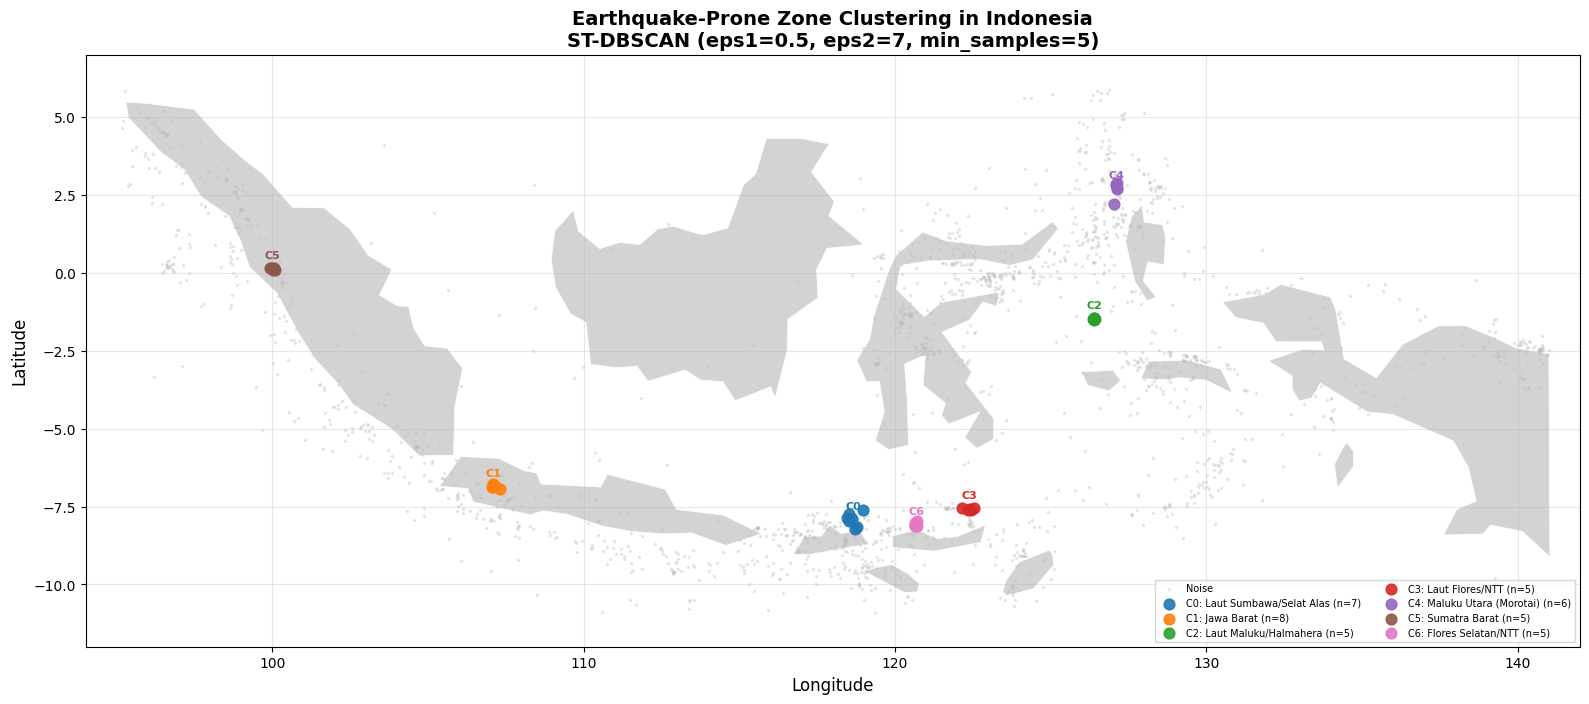

ST-DBSCAN map (English) saved!


In [23]:
#buat membuat peta persebaran klaster zona rawan gempa bumi Indonesia
#dengan background peta Indonesia menggunakan geopandas

#install geopandas dulu buat bisa load peta dunia
!pip install geopandas --quiet
import geopandas as gpd

#load shapefile peta dunia, lalu filter cuma wilayah Indonesia aja
world = gpd.read_file(
    "https://naciscdn.org/naturalearth/110m/cultural/ne_110m_admin_0_countries.zip"
)
indonesia = world[world['NAME'] == 'Indonesia']

#pisahin data yang masuk klaster vs yang noise
df_clustered = df_sample[df_sample['Cluster'] != -1]
df_noise = df_sample[df_sample['Cluster'] == -1]
colors = list(mcolors.TABLEAU_COLORS.values())

#mapping nomor klaster ke nama wilayah, biar legend-nya lebih informatif
wilayah_list = {
    0: 'Laut Sumbawa/Selat Alas', 1: 'Jawa Barat',
    2: 'Laut Maluku/Halmahera', 3: 'Laut Flores/NTT',
    4: 'Maluku Utara (Morotai)', 5: 'Sumatra Barat',
    6: 'Flores Selatan/NTT'
}

fig, ax = plt.subplots(figsize=(16, 8))

#gambar peta Indonesia sebagai background
indonesia.plot(ax=ax, color='lightgray', edgecolor='white', linewidth=0.5)

#plot titik-titik noise dengan warna abu-abu transparan
ax.scatter(df_noise['Longitude'], df_noise['Latitude'],
           c='silver', s=2, alpha=0.3, label='Noise')

#plot tiap klaster dengan warna berbeda, sekalian kasih label nama klaster + wilayah + jumlah anggota,
#dan tambahin anotasi teks "C{i}" di titik tengah tiap klaster
for i in sorted(df_clustered['Cluster'].unique()):
    cd = df_clustered[df_clustered['Cluster'] == i]
    ax.scatter(cd['Longitude'], cd['Latitude'],
               c=colors[i % len(colors)], s=60, alpha=0.9,
               label=f'C{i}: {wilayah_list[i]} (n={len(cd)})',
               zorder=5)
    cx = cd['Longitude'].mean()
    cy = cd['Latitude'].mean()
    ax.annotate(f'C{i}', (cx, cy), fontsize=8, fontweight='bold',
                ha='center', va='bottom',
                xytext=(0, 6), textcoords='offset points',
                color=colors[i % len(colors)])

#atur batas tampilan peta biar fokus ke wilayah Indonesia aja
ax.set_xlim(94, 142)
ax.set_ylim(-12, 7)
ax.set_xlabel('Longitude', fontsize=12)
ax.set_ylabel('Latitude', fontsize=12)
ax.set_title('Earthquake-Prone Zone Clustering in Indonesia\nST-DBSCAN (eps1=0.5, eps2=7, min_samples=5)',
             fontsize=14, fontweight='bold')
ax.legend(loc='lower right', fontsize=7, ncol=2)
ax.grid(True, alpha=0.3)

#simpan gambar dan tampilkan
plt.tight_layout()
plt.savefig('/drive/MyDrive/peta_cluster_stdbscan_map_en.png', dpi=300, bbox_inches='tight')
plt.show()
print("ST-DBSCAN map (English) saved!")

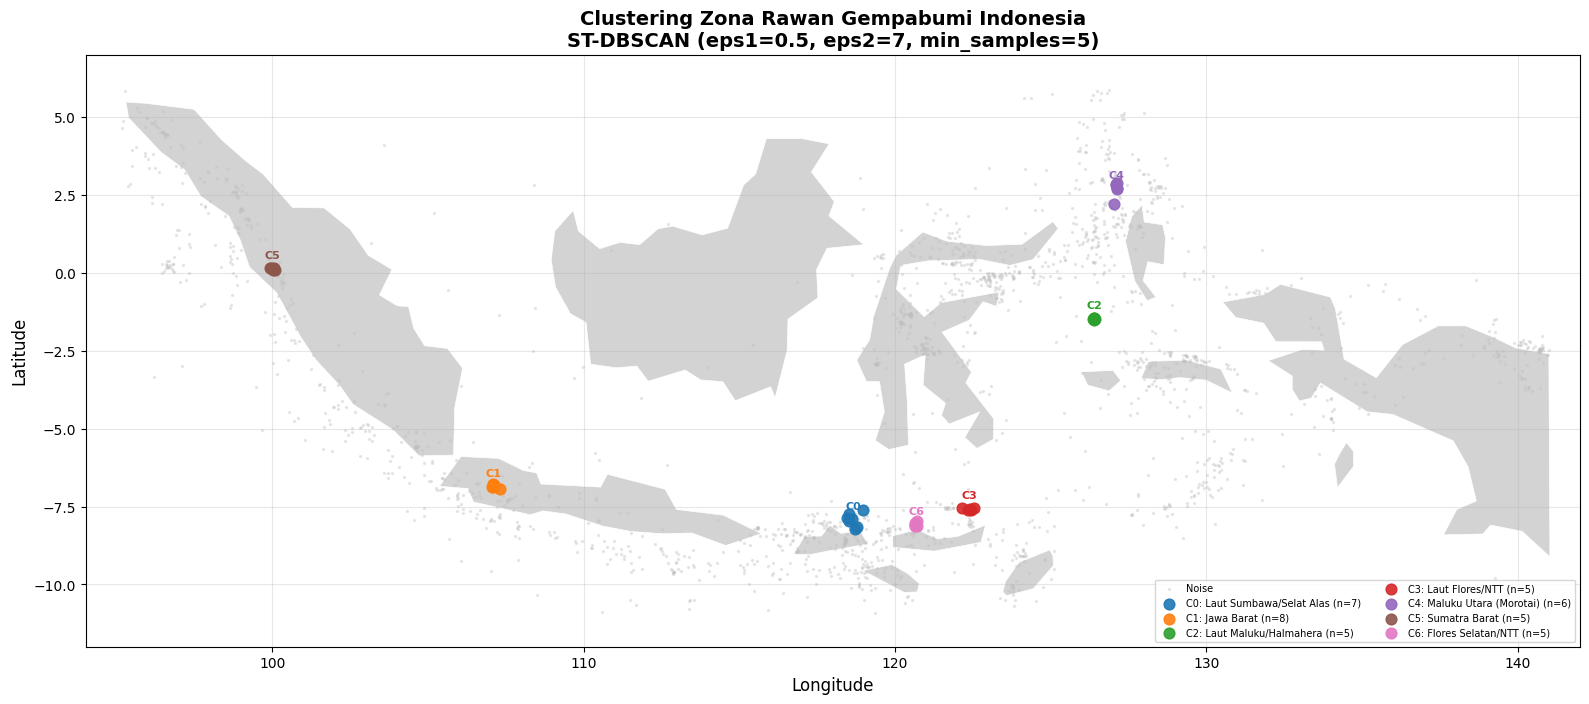

Peta ST-DBSCAN tersimpan!


In [24]:
#buat membuat peta persebaran klaster zona rawan gempa bumi Indonesia
#dengan background peta Indonesia menggunakan geopandas
#(versi bahasa Indonesia, pakai ulang peta "indonesia" yang udah di-load di cell sebelumnya)

#install geopandas dulu buat bisa load peta dunia
!pip install geopandas --quiet
import geopandas as gpd

#load shapefile peta dunia, lalu filter cuma wilayah Indonesia aja
world = gpd.read_file(
    "https://naciscdn.org/naturalearth/110m/cultural/ne_110m_admin_0_countries.zip"
)
indonesia = world[world['NAME'] == 'Indonesia']

#pisahin data yang masuk klaster vs yang noise
df_clustered = df_sample[df_sample['Cluster'] != -1]
df_noise = df_sample[df_sample['Cluster'] == -1]
colors = list(mcolors.TABLEAU_COLORS.values())

#mapping nomor klaster ke nama wilayah, biar legend-nya lebih informatif
wilayah_list = {
    0: 'Laut Sumbawa/Selat Alas', 1: 'Jawa Barat',
    2: 'Laut Maluku/Halmahera', 3: 'Laut Flores/NTT',
    4: 'Maluku Utara (Morotai)', 5: 'Sumatra Barat',
    6: 'Flores Selatan/NTT'
}

fig, ax = plt.subplots(figsize=(16, 8))

#gambar peta Indonesia sebagai background
indonesia.plot(ax=ax, color='lightgray', edgecolor='white', linewidth=0.5)

#plot titik-titik noise dengan warna abu-abu transparan
ax.scatter(df_noise['Longitude'], df_noise['Latitude'],
           c='silver', s=2, alpha=0.3, label='Noise')

#plot tiap klaster dengan warna berbeda, sekalian kasih label nama klaster + wilayah + jumlah anggota,
#dan tambahin anotasi teks "C{i}" di titik tengah tiap klaster
for i in sorted(df_clustered['Cluster'].unique()):
    cd = df_clustered[df_clustered['Cluster'] == i]
    ax.scatter(cd['Longitude'], cd['Latitude'],
               c=colors[i % len(colors)], s=60, alpha=0.9,
               label=f'C{i}: {wilayah_list[i]} (n={len(cd)})',
               zorder=5)
    cx = cd['Longitude'].mean()
    cy = cd['Latitude'].mean()
    ax.annotate(f'C{i}', (cx, cy), fontsize=8, fontweight='bold',
                ha='center', va='bottom',
                xytext=(0, 6), textcoords='offset points',
                color=colors[i % len(colors)])

#atur batas tampilan peta biar fokus ke wilayah Indonesia aja
ax.set_xlim(94, 142)
ax.set_ylim(-12, 7)
ax.set_xlabel('Longitude', fontsize=12)
ax.set_ylabel('Latitude', fontsize=12)
ax.set_title('Clustering Zona Rawan Gempabumi Indonesia\nST-DBSCAN (eps1=0.5, eps2=7, min_samples=5)',
             fontsize=14, fontweight='bold')
ax.legend(loc='lower right', fontsize=7, ncol=2)
ax.grid(True, alpha=0.3)

#simpan gambar dan tampilkan
plt.tight_layout()
plt.savefig('/drive/MyDrive/peta_cluster_stdbscan_map.png', dpi=300, bbox_inches='tight')
plt.show()
print("Peta ST-DBSCAN tersimpan!")

In [25]:
#buat menghitung karakteristik lengkap tiap klaster meliputi jumlah anggota,
#statistik magnitudo, kedalaman, serta koordinat pusat klaster

#group by nomor klaster (buang noise / -1), terus hitung beberapa statistik:
#jumlah anggota, rata-rata/maks/min magnitudo, rata-rata/min/maks kedalaman,
#dan rata-rata lat-lon sebagai titik pusat klaster
cluster_stats = df_sample[df_sample['Cluster'] != -1].groupby('Cluster').agg(
    Jumlah=('Magnitude', 'count'),
    Mag_mean=('Magnitude', 'mean'),
    Mag_max=('Magnitude', 'max'),
    Mag_min=('Magnitude', 'min'),
    Depth_mean=('Depth (km)', 'mean'),
    Depth_min=('Depth (km)', 'min'),
    Depth_max=('Depth (km)', 'max'),
    Lat_mean=('Latitude', 'mean'),
    Lon_mean=('Longitude', 'mean')
).round(2)

print("=== KARAKTERISTIK CLUSTER LENGKAP ===")
print(cluster_stats.to_string())

=== KARAKTERISTIK CLUSTER LENGKAP ===
         Jumlah  Mag_mean  Mag_max  Mag_min  Depth_mean  Depth_min  Depth_max  Lat_mean  Lon_mean
Cluster                                                                                          
0             7      2.76     3.01     2.55       27.14         10         75     -7.92    118.65
1             8      2.05     4.17     1.25       16.25         10         31     -6.85    107.11
2             5      3.93     4.12     3.80       13.20         10         16     -1.47    126.39
3             5      2.99     3.37     2.65       20.60         10         38     -7.58    122.38
4             6      3.64     4.25     3.08       25.33         10         82      2.69    127.10
5             5      3.22     4.23     2.43       10.00         10         10      0.13    100.00
6             5      3.74     4.52     2.99       11.00         10         15     -8.07    120.67


In [26]:
#buat nampilin koordinat pusat tiap klaster untuk identifikasi wilayah geografis
print("=== KOORDINAT PUSAT TIAP CLUSTER ===")

#loop tiap baris cluster_stats, terus print info ringkas per klaster:
#jumlah anggota, koordinat pusat (lat, lon), magnitudo rata-rata & maks, dan kedalaman rata-rata
for i, row in cluster_stats.iterrows():
    print(f"Cluster {i:2d} | n={int(row['Jumlah']):3d} | "
          f"Lat={row['Lat_mean']:7.2f}, Lon={row['Lon_mean']:7.2f} | "
          f"Mag avg={row['Mag_mean']:.2f}, max={row['Mag_max']:.2f} | "
          f"Depth avg={row['Depth_mean']:.1f} km")

=== KOORDINAT PUSAT TIAP CLUSTER ===
Cluster  0 | n=  7 | Lat=  -7.92, Lon= 118.65 | Mag avg=2.76, max=3.01 | Depth avg=27.1 km
Cluster  1 | n=  8 | Lat=  -6.85, Lon= 107.11 | Mag avg=2.05, max=4.17 | Depth avg=16.2 km
Cluster  2 | n=  5 | Lat=  -1.47, Lon= 126.39 | Mag avg=3.93, max=4.12 | Depth avg=13.2 km
Cluster  3 | n=  5 | Lat=  -7.58, Lon= 122.38 | Mag avg=2.99, max=3.37 | Depth avg=20.6 km
Cluster  4 | n=  6 | Lat=   2.69, Lon= 127.10 | Mag avg=3.64, max=4.25 | Depth avg=25.3 km
Cluster  5 | n=  5 | Lat=   0.13, Lon= 100.00 | Mag avg=3.22, max=4.23 | Depth avg=10.0 km
Cluster  6 | n=  5 | Lat=  -8.07, Lon= 120.67 | Mag avg=3.74, max=4.52 | Depth avg=11.0 km


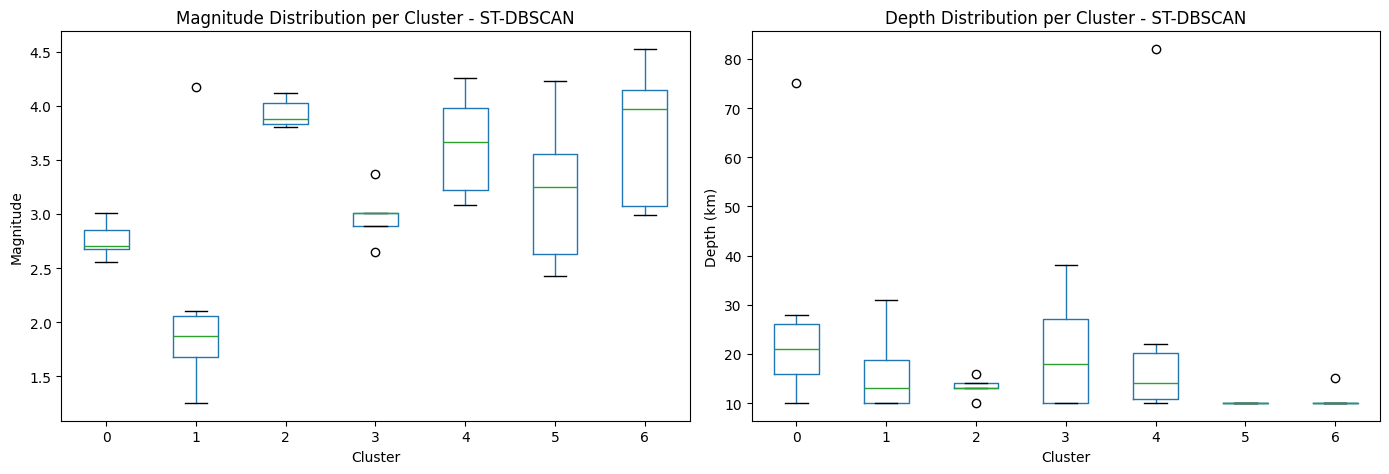

ST-DBSCAN boxplot (English) saved!


In [27]:
#buat nampilin boxplot distribusi magnitudo dan kedalaman untuk tiap klaster
#dalam satu figure dengan dua subplot berdampingan

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

#ambil data yang udah ke-cluster aja (buang noise)
df_cl = df_sample[df_sample['Cluster'] != -1].copy()

#subplot kiri: boxplot magnitudo per klaster
df_cl.boxplot(column='Magnitude', by='Cluster', ax=axes[0], grid=False)
axes[0].set_xlabel('Cluster')
axes[0].set_ylabel('Magnitude')
plt.sca(axes[0])
plt.title('Magnitude Distribution per Cluster - ST-DBSCAN')

#subplot kanan: boxplot kedalaman per klaster
df_cl.boxplot(column='Depth (km)', by='Cluster', ax=axes[1], grid=False)
axes[1].set_xlabel('Cluster')
axes[1].set_ylabel('Depth (km)')
plt.sca(axes[1])
plt.title('Depth Distribution per Cluster - ST-DBSCAN')

#hapus judul besar otomatis dari pandas boxplot biar gak dobel sama title masing-masing subplot
plt.suptitle('')
plt.tight_layout()
plt.savefig('/drive/MyDrive/boxplot_cluster_en.png', dpi=300, bbox_inches='tight')
plt.show()
print("ST-DBSCAN boxplot (English) saved!")

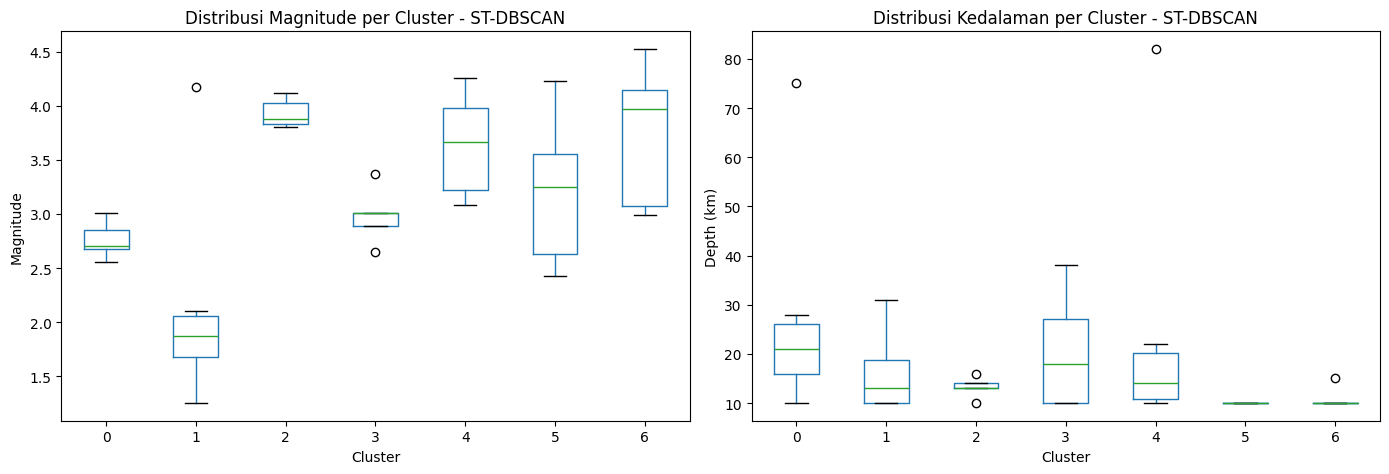

Boxplot tersimpan!


In [28]:
#buat nampilin boxplot distribusi magnitudo dan kedalaman untuk tiap klaster
#dalam satu figure dengan dua subplot berdampingan
#(versi bahasa Indonesia)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

#ambil data yang udah ke-cluster aja (buang noise)
df_cl = df_sample[df_sample['Cluster'] != -1].copy()

#subplot kiri: boxplot magnitudo per klaster
df_cl.boxplot(column='Magnitude', by='Cluster', ax=axes[0], grid=False)
axes[0].set_xlabel('Cluster')
axes[0].set_ylabel('Magnitude')
plt.sca(axes[0])
plt.title('Distribusi Magnitude per Cluster - ST-DBSCAN')

#subplot kanan: boxplot kedalaman per klaster
df_cl.boxplot(column='Depth (km)', by='Cluster', ax=axes[1], grid=False)
axes[1].set_xlabel('Cluster')
axes[1].set_ylabel('Depth (km)')
plt.sca(axes[1])
plt.title('Distribusi Kedalaman per Cluster - ST-DBSCAN')

#hapus judul besar otomatis dari pandas boxplot biar gak dobel sama title masing-masing subplot
plt.suptitle('')
plt.tight_layout()
plt.savefig('/drive/MyDrive/boxplot_cluster.png', dpi=300, bbox_inches='tight')
plt.show()
print("Boxplot tersimpan!")

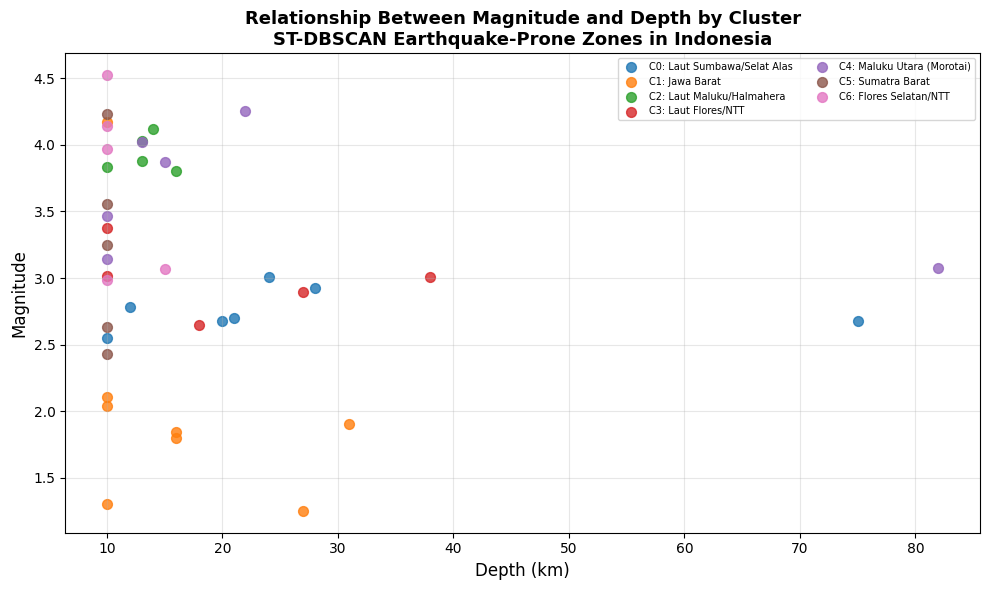

ST-DBSCAN scatter plot (English) saved!


In [29]:
#buat nampilin scatter plot hubungan magnitudo dan kedalaman untuk tiap klaster
#biar bisa lihat pola dan pencilan antar klaster secara visual

#mapping nomor klaster ke nama wilayah buat legend
wilayah = {
    0: 'Laut Sumbawa/Selat Alas', 1: 'Jawa Barat', 2: 'Laut Maluku/Halmahera',
    3: 'Laut Flores/NTT', 4: 'Maluku Utara (Morotai)',
    5: 'Sumatra Barat', 6: 'Flores Selatan/NTT'
}

#ambil data yang udah ke-cluster aja (buang noise)
df_cl = df_sample[df_sample['Cluster'] != -1].copy()

fig, ax = plt.subplots(figsize=(10, 6))

#scatter tiap klaster dengan warna beda, sumbu x = kedalaman, sumbu y = magnitudo
for i in range(n_clusters):
    cd = df_cl[df_cl['Cluster'] == i]
    ax.scatter(cd['Depth (km)'], cd['Magnitude'],
               c=colors[i], s=50, alpha=0.8,
               label=f'C{i}: {wilayah[i]}')

ax.set_xlabel('Depth (km)', fontsize=12)
ax.set_ylabel('Magnitude', fontsize=12)
ax.set_title('Relationship Between Magnitude and Depth by Cluster\nST-DBSCAN Earthquake-Prone Zones in Indonesia',
             fontsize=13, fontweight='bold')
ax.legend(loc='upper right', fontsize=7, ncol=2)
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('/drive/MyDrive/scatter_mag_depth_en.png', dpi=300, bbox_inches='tight')
plt.show()
print("ST-DBSCAN scatter plot (English) saved!")

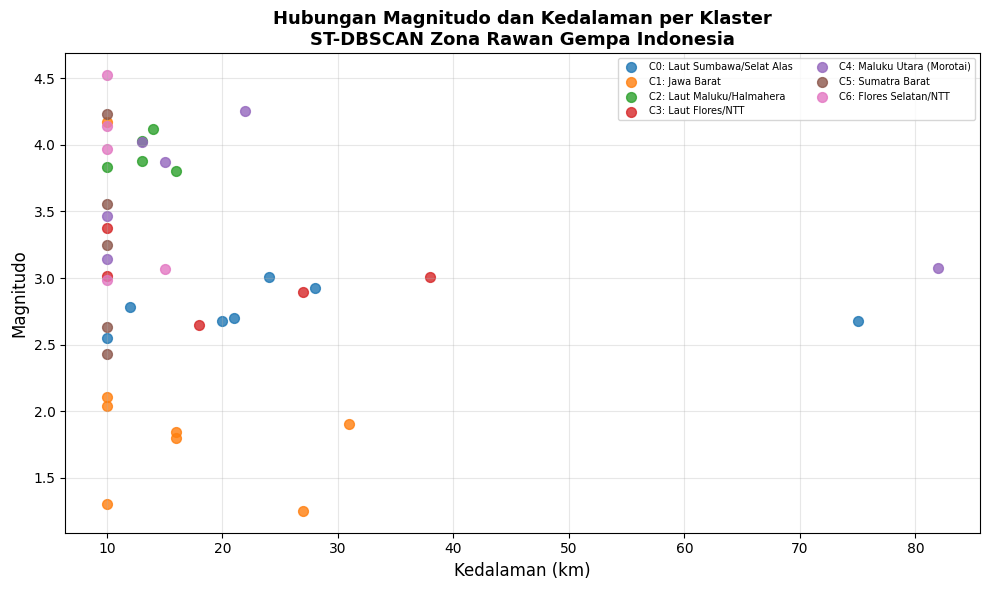

Scatter plot tersimpan!


In [30]:
#buat nampilin scatter plot hubungan magnitudo dan kedalaman untuk tiap klaster
#biar bisa lihat pola dan pencilan antar klaster secara visual
#(versi bahasa Indonesia)

#mapping nomor klaster ke nama wilayah buat legend
wilayah = {
    0: 'Laut Sumbawa/Selat Alas', 1: 'Jawa Barat', 2: 'Laut Maluku/Halmahera',
    3: 'Laut Flores/NTT', 4: 'Maluku Utara (Morotai)',
    5: 'Sumatra Barat', 6: 'Flores Selatan/NTT'
}

#ambil data yang udah ke-cluster aja (buang noise)
df_cl = df_sample[df_sample['Cluster'] != -1].copy()

fig, ax = plt.subplots(figsize=(10, 6))

#scatter tiap klaster dengan warna beda, sumbu x = kedalaman, sumbu y = magnitudo
for i in range(n_clusters):
    cd = df_cl[df_cl['Cluster'] == i]
    ax.scatter(cd['Depth (km)'], cd['Magnitude'],
               c=colors[i], s=50, alpha=0.8,
               label=f'C{i}: {wilayah[i]}')

ax.set_xlabel('Kedalaman (km)', fontsize=12)
ax.set_ylabel('Magnitudo', fontsize=12)
ax.set_title('Hubungan Magnitudo dan Kedalaman per Klaster\nST-DBSCAN Zona Rawan Gempa Indonesia',
             fontsize=13, fontweight='bold')
ax.legend(loc='upper right', fontsize=7, ncol=2)
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('/drive/MyDrive/scatter_mag_depth.png', dpi=300, bbox_inches='tight')
plt.show()
print("Scatter plot tersimpan!")

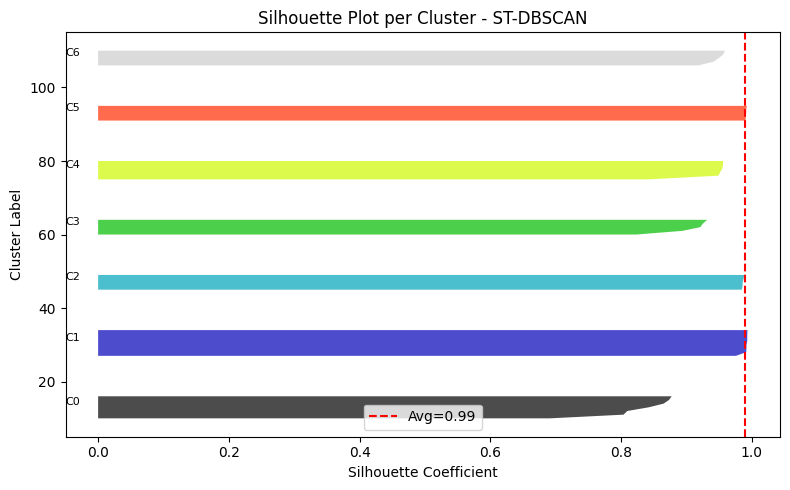

ST-DBSCAN silhouette plot (English) saved!


In [31]:
#buat nampilin silhouette plot untuk mengevaluasi kualitas tiap klaster secara visual,
#tiap klaster ditampilkan dengan warna berbeda dan garis merah menunjukkan rata-rata silhouette

#ambil data yang udah ke-cluster aja (buang noise)
df_cl2 = df_sample[df_sample['Cluster'] != -1]
X_eval = df_cl2[['Latitude', 'Longitude']].values
labels_eval = df_cl2['Cluster'].values

#hitung silhouette score per titik data
sample_silhouette_values = silhouette_samples(X_eval, labels_eval)

fig, ax = plt.subplots(figsize=(8, 5))
y_lower = 10

#bikin warna berbeda untuk tiap klaster
colors_sil = cm.nipy_spectral(np.linspace(0, 1, n_clusters))

#loop tiap klaster, urutkan nilai silhouette-nya, terus gambar sebagai "pita" horizontal
for i in range(n_clusters):
    ith_sil = np.sort(sample_silhouette_values[labels_eval == i])
    y_upper = y_lower + len(ith_sil)
    ax.fill_betweenx(np.arange(y_lower, y_upper), 0, ith_sil,
                     facecolor=colors_sil[i], alpha=0.7)
    ax.text(-0.05, y_lower + len(ith_sil)/2, f'C{i}', fontsize=8)
    y_lower = y_upper + 10

#garis vertikal merah menunjukkan rata-rata silhouette score keseluruhan
ax.axvline(x=sil_best, color="red", linestyle="--", label=f'Avg={round(sil_best,3)}')
ax.set_title('Silhouette Plot per Cluster - ST-DBSCAN')
ax.set_xlabel('Silhouette Coefficient')
ax.set_ylabel('Cluster Label')
ax.legend()
plt.tight_layout()
plt.savefig('/drive/MyDrive/silhouette_plot_en.png', dpi=300, bbox_inches='tight')
plt.show()
print("ST-DBSCAN silhouette plot (English) saved!")

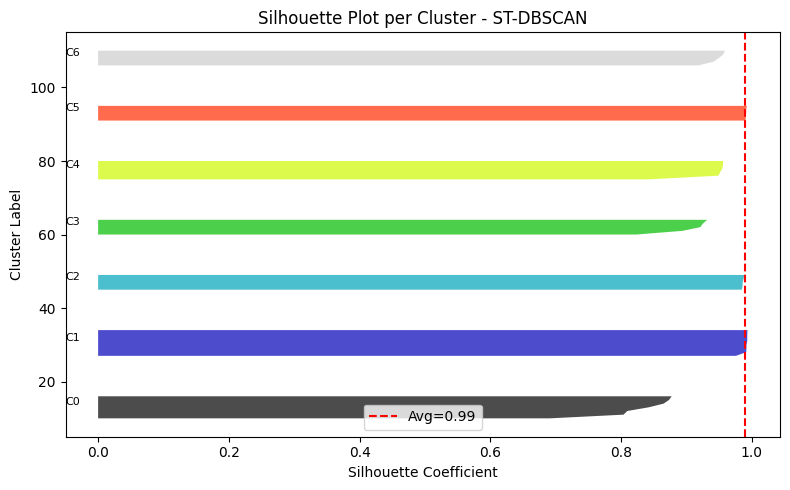

Silhouette plot tersimpan!


In [32]:
#buat nampilin silhouette plot untuk mengevaluasi kualitas tiap klaster secara visual,
#tiap klaster ditampilkan dengan warna berbeda dan garis merah menunjukkan rata-rata silhouette
#(versi bahasa Indonesia)

#ambil data yang udah ke-cluster aja (buang noise)
df_cl2 = df_sample[df_sample['Cluster'] != -1]
X_eval = df_cl2[['Latitude', 'Longitude']].values
labels_eval = df_cl2['Cluster'].values

#hitung silhouette score per titik data
sample_silhouette_values = silhouette_samples(X_eval, labels_eval)

fig, ax = plt.subplots(figsize=(8, 5))
y_lower = 10

#bikin warna berbeda untuk tiap klaster
colors_sil = cm.nipy_spectral(np.linspace(0, 1, n_clusters))

#loop tiap klaster, urutkan nilai silhouette-nya, terus gambar sebagai "pita" horizontal
for i in range(n_clusters):
    ith_sil = np.sort(sample_silhouette_values[labels_eval == i])
    y_upper = y_lower + len(ith_sil)
    ax.fill_betweenx(np.arange(y_lower, y_upper), 0, ith_sil,
                     facecolor=colors_sil[i], alpha=0.7)
    ax.text(-0.05, y_lower + len(ith_sil)/2, f'C{i}', fontsize=8)
    y_lower = y_upper + 10

#garis vertikal merah menunjukkan rata-rata silhouette score keseluruhan
ax.axvline(x=sil_best, color="red", linestyle="--", label=f'Avg={round(sil_best,3)}')
ax.set_title('Silhouette Plot per Cluster - ST-DBSCAN')
ax.set_xlabel('Silhouette Coefficient')
ax.set_ylabel('Cluster Label')
ax.legend()
plt.tight_layout()
plt.savefig('/drive/MyDrive/silhouette_plot.png', dpi=300, bbox_inches='tight')
plt.show()
print("Silhouette plot tersimpan!")

In [33]:
#buat nampilin tabel ringkasan hasil clustering lengkap dengan nama wilayah
#yang siap dijadikan referensi untuk penulisan paper

#daftar nama wilayah sesuai urutan nomor klaster 0-6
wilayah_list = [
    'Laut Sumbawa/Selat Alas', 'Jawa Barat', 'Laut Maluku/Halmahera',
    'Laut Flores/NTT', 'Maluku Utara (Morotai)',
    'Sumatra Barat', 'Flores Selatan/NTT'
]

#tambahin kolom nama wilayah ke tabel cluster_stats
cluster_stats['Wilayah'] = wilayah_list
cols_show = ['Wilayah', 'Jumlah', 'Mag_mean', 'Mag_max', 'Depth_mean', 'Lat_mean', 'Lon_mean']

#tampilin tabel final yang siap dicopy ke paper
print("=== TABEL HASIL CLUSTER (untuk paper) ===")
print(cluster_stats[cols_show].to_string())

=== TABEL HASIL CLUSTER (untuk paper) ===
                         Wilayah  Jumlah  Mag_mean  Mag_max  Depth_mean  Lat_mean  Lon_mean
Cluster                                                                                    
0        Laut Sumbawa/Selat Alas       7      2.76     3.01       27.14     -7.92    118.65
1                     Jawa Barat       8      2.05     4.17       16.25     -6.85    107.11
2          Laut Maluku/Halmahera       5      3.93     4.12       13.20     -1.47    126.39
3                Laut Flores/NTT       5      2.99     3.37       20.60     -7.58    122.38
4         Maluku Utara (Morotai)       6      3.64     4.25       25.33      2.69    127.10
5                  Sumatra Barat       5      3.22     4.23       10.00      0.13    100.00
6             Flores Selatan/NTT       5      3.74     4.52       11.00     -8.07    120.67


In [34]:
#buat mencari parameter optimal ST-OPTICS menggunakan grid search
#dengan sampling 2000 data untuk efisiensi komputasi

#install library st_optics dulu
!pip install st_optics --quiet
from st_optics import ST_OPTICS

#sampling 2000 data khusus buat grid search ST-OPTICS (random_state sama biar konsisten)
df_grid_optics = df_clean.sample(n=2000, random_state=42).reset_index(drop=True)
X_spatial_optics = df_grid_optics[['Latitude', 'Longitude']].values
X_temporal_optics = df_grid_optics[['Time_days']].values

#daftar nilai yang mau dicoba untuk masing-masing parameter ST-OPTICS
xi_list = [0.3, 0.4, 0.5]
eps2_list = [7, 14, 30]
min_samples_list = [3, 5, 10]

#list buat nyimpen hasil tiap kombinasi parameter
results_optics = []

#looping semua kombinasi xi, eps2, min_samples (3x3x3 = 27 kombinasi)
for xi in xi_list:
    for eps2 in eps2_list:
        for min_samples in min_samples_list:
            #jalankan ST-OPTICS dengan kombinasi parameter saat ini
            st_optics = ST_OPTICS(xi=xi, eps2=eps2, min_samples=min_samples)
            st_optics.fit(np.column_stack([X_spatial_optics, X_temporal_optics]))
            labels = st_optics.labels

            #hitung jumlah klaster dan jumlah noise
            n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
            n_noise = list(labels).count(-1)
            n_clustered = len(labels) - n_noise

            #hitung silhouette score kalau memenuhi syarat (minimal 2 klaster, ada titik ke-cluster)
            sil_score = None
            if n_clusters >= 2 and n_clustered > 1:
                try:
                    sil_score = silhouette_score(
                        np.column_stack([X_spatial_optics, X_temporal_optics])[labels != -1],
                        labels[labels != -1]
                    )
                except:
                    sil_score = None

            #simpan hasil kombinasi ini
            results_optics.append({
                'xi': xi, 'eps2': eps2, 'min_samples': min_samples,
                'n_clusters': n_clusters, 'n_noise': n_noise,
                'n_clustered': n_clustered, 'silhouette': sil_score
            })

            #print progress
            print(f"xi={xi}, eps2={eps2}, min_samples={min_samples} \u2192 clusters={n_clusters}, noise={n_noise}, sil={round(sil_score,3) if sil_score else 'N/A'}")

print("\nSelesai!")

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 157.6/157.6 kB 3.2 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
xi=0.3, eps2=7, min_samples=3 → clusters=150, noise=1357, sil=0.661
xi=0.3, eps2=7, min_samples=5 → clusters=28, noise=1789, sil=0.833
xi=0.3, eps2=7, min_samples=10 → clusters=2, noise=1978, sil=0.991
xi=0.3, eps2=14, min_samples=3 → clusters=145, noise=1383, sil=0.62
xi=0.3, eps2=14, min_samples=5 → clusters=26, noise=1791, sil=0.851
xi=0.3, eps2=14, min_samples=10 → clusters=4, noise=1931, sil=0.915
xi=0.3, eps2=30, min_samples=3 → clusters=145, noise=1383, sil=0.62
xi=0.3, eps2=30, min_samples=5 → clusters=26, noise=1791, sil=0.851
xi=0.3, eps2=30, min_samples=10 → clusters=4, noise=1931, sil=0.915
xi=0.4, eps2=7, min_samples=3 → clusters=103, noise=1582, sil=0.755
xi=0.4, eps2=7, min_samples=5 → clusters=19, noise=1863, sil=0.904
xi=0.4, eps2=7, min_samples=10 → clusters=2, noise=1979, sil=0.993
xi=0.4, eps2=14, min_samples=3 → clusters=99, noise=1605, sil=0.70

In [35]:
#buat nampilin 10 kombinasi parameter terbaik ST-OPTICS berdasarkan Silhouette Score tertinggi
#dan menampilkan parameter optimal yang akan digunakan untuk clustering final

#ubah hasil grid search jadi dataframe, buang yang silhouette-nya None,
#lalu urutkan dari silhouette tertinggi ke terendah
df_results_optics = pd.DataFrame(results_optics)
df_results_optics = df_results_optics.dropna(subset=['silhouette'])
df_results_optics = df_results_optics.sort_values('silhouette', ascending=False)

#tampilin 10 kombinasi terbaik
print("=== 10 PARAMETER TERBAIK ST-OPTICS ===")
print(df_results_optics.head(10).to_string(index=False))

#ambil baris paling atas sebagai kandidat parameter terbaik
best_optics = df_results_optics.iloc[0]
print(f"\n=== PARAMETER TERBAIK ST-OPTICS ===")
print(f"xi         : {best_optics['xi']}")
print(f"eps2       : {best_optics['eps2']}")
print(f"min_samples: {best_optics['min_samples']}")
print(f"Clusters   : {best_optics['n_clusters']}")
print(f"Noise      : {best_optics['n_noise']}")
print(f"Silhouette : {round(best_optics['silhouette'], 3)}")

=== 10 PARAMETER TERBAIK ST-OPTICS ===
 xi  eps2  min_samples  n_clusters  n_noise  n_clustered  silhouette
0.4    30           10           2     1979           21    0.993074
0.4    14           10           2     1979           21    0.993074
0.4     7           10           2     1979           21    0.993074
0.5     7           10           2     1979           21    0.993074
0.5    14           10           2     1979           21    0.993074
0.5    30           10           2     1979           21    0.993074
0.3     7           10           2     1978           22    0.990979
0.5    30            5          12     1918           82    0.943879
0.5    14            5          12     1918           82    0.943879
0.5     7            5          11     1925           75    0.943023

=== PARAMETER TERBAIK ST-OPTICS ===
xi         : 0.4
eps2       : 30.0
min_samples: 10.0
Clusters   : 2.0
Noise      : 1979.0
Silhouette : 0.993


In [36]:
#buat menjalankan ST-OPTICS dengan parameter optimal
#final run menggunakan 2000 sampel data

#sampling 2000 data lagi buat final run ST-OPTICS (sama dengan sample ST-DBSCAN, random_state=42)
df_final_optics = df_clean.sample(n=2000, random_state=42).reset_index(drop=True)
X_spatial_optics = df_final_optics[['Latitude', 'Longitude']].values
X_temporal_optics = df_final_optics[['Time_days']].values

#parameter terbaik yang dipilih (lihat penjelasan paper soal alasan pemilihan parameter ini)
best_xi = 0.5
best_eps2_optics = 7
best_min_samples_optics = 5

#jalankan ST-OPTICS dengan parameter terbaik
st_optics_best = ST_OPTICS(xi=best_xi, eps2=best_eps2_optics,
                            min_samples=best_min_samples_optics)
st_optics_best.fit(np.column_stack([X_spatial_optics, X_temporal_optics]))
labels_optics = st_optics_best.labels

#simpan hasil label cluster ke dataframe df_final_optics
df_final_optics['Cluster_OPTICS'] = labels_optics

#hitung jumlah klaster dan jumlah noise
n_clusters_optics = len(set(labels_optics)) - (1 if -1 in labels_optics else 0)
n_noise_optics = list(labels_optics).count(-1)

#hitung silhouette score buat klaster final (tanpa noise)
mask_optics = labels_optics != -1
sil_optics = silhouette_score(
    np.column_stack([X_spatial_optics, X_temporal_optics])[mask_optics],
    labels_optics[mask_optics]
)

#tampilin ringkasan hasil akhir ST-OPTICS
print(f"=== HASIL AKHIR ST-OPTICS (SAMPLE 2000) ===")
print(f"Parameter  : xi={best_xi}, eps2={best_eps2_optics}, min_samples={best_min_samples_optics}")
print(f"Cluster    : {n_clusters_optics}")
print(f"Noise      : {n_noise_optics} ({round(n_noise_optics/2000*100,1)}%)")
print(f"Ter-cluster: {2000-n_noise_optics}")
print(f"Silhouette : {round(sil_optics,3)}")

=== HASIL AKHIR ST-OPTICS (SAMPLE 2000) ===
Parameter  : xi=0.5, eps2=7, min_samples=5
Cluster    : 11
Noise      : 1925 (96.2%)
Ter-cluster: 75
Silhouette : 0.943


In [37]:
#buat nampilin tabel perbandingan hasil ST-DBSCAN dan ST-OPTICS
#berdasarkan jumlah klaster, noise, silhouette score, dan davies-bouldin index

from sklearn.metrics import davies_bouldin_score

#hitung silhouette score dan davies-bouldin index untuk ST-DBSCAN
mask_stdbscan = df_sample['Cluster'] != -1
sil_stdbscan = silhouette_score(
    np.column_stack([X_spatial, X_temporal])[mask_stdbscan],
    df_sample['Cluster'].values[mask_stdbscan]
)
db_stdbscan = davies_bouldin_score(
    np.column_stack([X_spatial, X_temporal])[mask_stdbscan],
    df_sample['Cluster'].values[mask_stdbscan]
)

#hitung silhouette score dan davies-bouldin index untuk ST-OPTICS
mask_optics = df_final_optics['Cluster_OPTICS'] != -1
sil_optics_final = silhouette_score(
    np.column_stack([X_spatial_optics, X_temporal_optics])[mask_optics],
    df_final_optics['Cluster_OPTICS'].values[mask_optics]
)
db_optics_final = davies_bouldin_score(
    np.column_stack([X_spatial_optics, X_temporal_optics])[mask_optics],
    df_final_optics['Cluster_OPTICS'].values[mask_optics]
)

#tampilin tabel perbandingan kedua algoritma berdampingan
print("=" * 65)
print(f"{'Metrik':<30} {'ST-DBSCAN':>16} {'ST-OPTICS':>16}")
print("=" * 65)
print(f"{'Jumlah Data':<30} {'2.000':>16} {'2.000':>16}")
print(f"{'Jumlah Klaster':<30} {'7':>16} {'11':>16}")
print(f"{'Jumlah Noise':<30} {'1959 (98.0%)':>16} {'1925 (96.2%)':>16}")
print(f"{'Silhouette Score':<30} {sil_stdbscan:>16.3f} {sil_optics_final:>16.3f}")
print(f"{'Davies-Bouldin Index':<30} {db_stdbscan:>16.3f} {db_optics_final:>16.3f}")
print("=" * 65)
print("* Silhouette Score    : lebih tinggi lebih baik (maks 1)")
print("* Davies-Bouldin Index: lebih rendah lebih baik (min 0)")

Metrik                                ST-DBSCAN        ST-OPTICS
Jumlah Data                               2.000            2.000
Jumlah Klaster                                7               11
Jumlah Noise                       1959 (98.0%)     1925 (96.2%)
Silhouette Score                          0.990            0.943
Davies-Bouldin Index                      0.013            0.076
* Silhouette Score    : lebih tinggi lebih baik (maks 1)
* Davies-Bouldin Index: lebih rendah lebih baik (min 0)


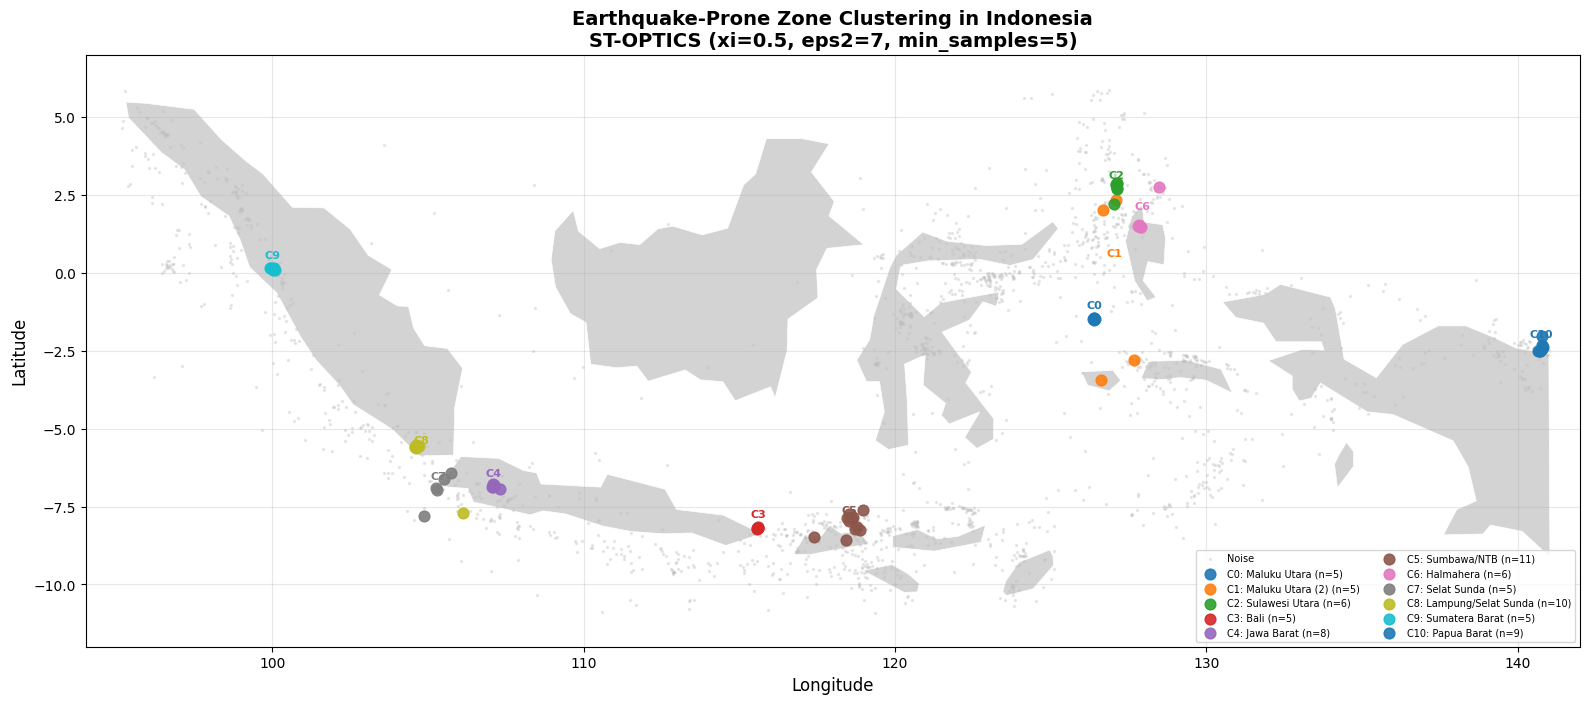

ST-OPTICS map (English) saved!


In [38]:
#buat membuat peta persebaran klaster zona rawan gempa bumi Indonesia
#hasil ST-OPTICS dengan background peta Indonesia

#pisahin data yang masuk klaster vs yang noise
df_clustered_optics = df_final_optics[df_final_optics['Cluster_OPTICS'] != -1]
df_noise_optics = df_final_optics[df_final_optics['Cluster_OPTICS'] == -1]
colors = list(mcolors.TABLEAU_COLORS.values())

#mapping nomor klaster ke nama wilayah buat legend (11 klaster ST-OPTICS)
wilayah_optics = {
    0: 'Maluku Utara', 1: 'Maluku Utara (2)', 2: 'Sulawesi Utara',
    3: 'Bali', 4: 'Jawa Barat', 5: 'Sumbawa/NTB',
    6: 'Halmahera', 7: 'Selat Sunda', 8: 'Lampung/Selat Sunda',
    9: 'Sumatera Barat', 10: 'Papua Barat'
}

fig, ax = plt.subplots(figsize=(16, 8))

#gambar peta Indonesia sebagai background (variabel "indonesia" sudah di-load di cell ST-DBSCAN sebelumnya)
indonesia.plot(ax=ax, color='lightgray', edgecolor='white', linewidth=0.5)

#plot titik-titik noise dengan warna abu-abu transparan
ax.scatter(df_noise_optics['Longitude'], df_noise_optics['Latitude'],
           c='silver', s=2, alpha=0.3, label='Noise')

#plot tiap klaster dengan warna berbeda, sekalian kasih label nama klaster + wilayah + jumlah anggota,
#dan tambahin anotasi teks "C{i}" di titik tengah tiap klaster
for i in sorted(df_clustered_optics['Cluster_OPTICS'].unique()):
    cd = df_clustered_optics[df_clustered_optics['Cluster_OPTICS'] == i]
    ax.scatter(cd['Longitude'], cd['Latitude'],
               c=colors[i % len(colors)], s=60, alpha=0.9,
               label=f'C{i}: {wilayah_optics[i]} (n={len(cd)})',
               zorder=5)
    cx = cd['Longitude'].mean()
    cy = cd['Latitude'].mean()
    ax.annotate(f'C{i}', (cx, cy), fontsize=8, fontweight='bold',
                ha='center', va='bottom',
                xytext=(0, 6), textcoords='offset points',
                color=colors[i % len(colors)])

#atur batas tampilan peta biar fokus ke wilayah Indonesia aja
ax.set_xlim(94, 142)
ax.set_ylim(-12, 7)
ax.set_xlabel('Longitude', fontsize=12)
ax.set_ylabel('Latitude', fontsize=12)
ax.set_title('Earthquake-Prone Zone Clustering in Indonesia\nST-OPTICS (xi=0.5, eps2=7, min_samples=5)',
             fontsize=14, fontweight='bold')
ax.legend(loc='lower right', fontsize=7, ncol=2)
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('/drive/MyDrive/peta_cluster_stoptics_en.png', dpi=300, bbox_inches='tight')
plt.show()
print("ST-OPTICS map (English) saved!")

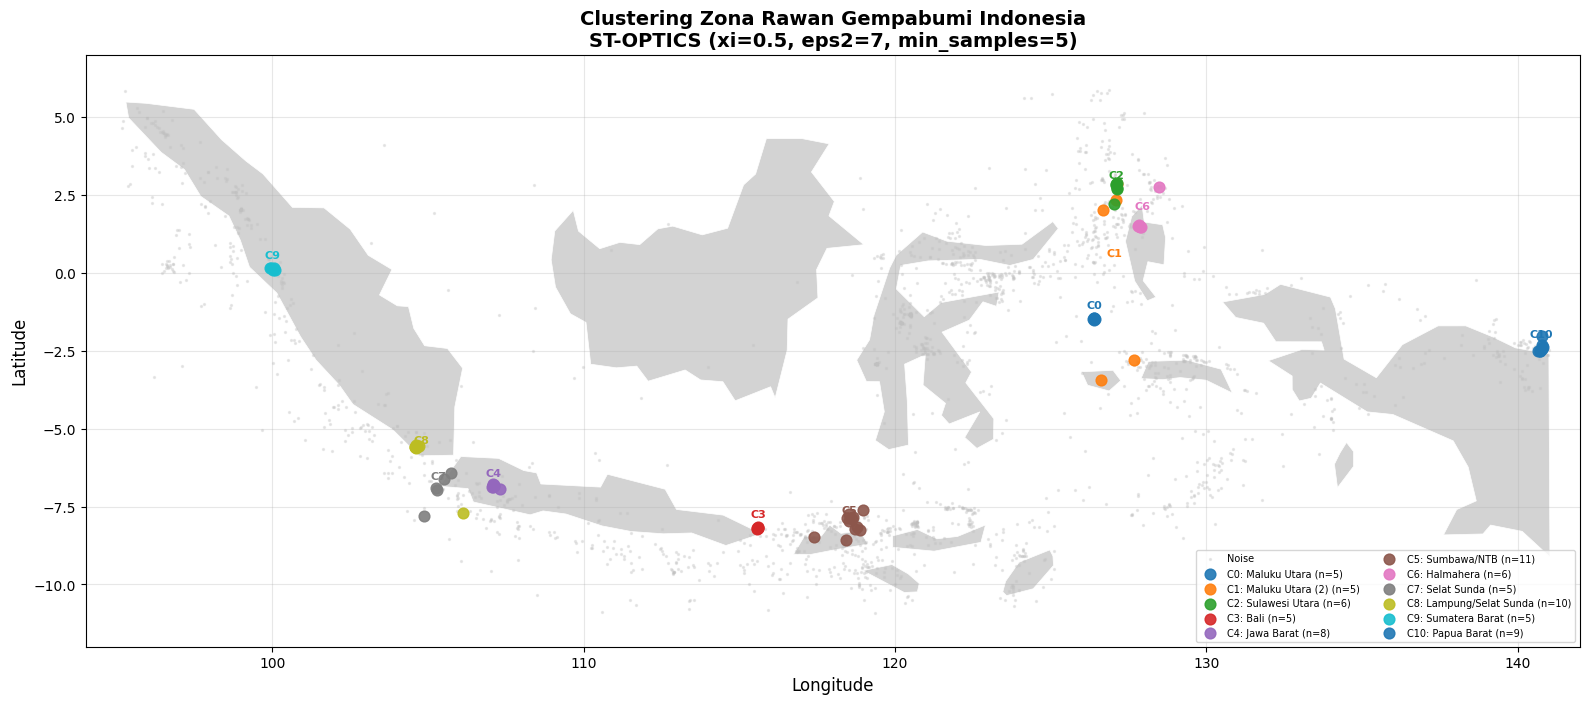

Peta ST-OPTICS tersimpan!


In [39]:
#buat membuat peta persebaran klaster zona rawan gempa bumi Indonesia
#hasil ST-OPTICS dengan background peta Indonesia
#(versi bahasa Indonesia)

#pisahin data yang masuk klaster vs yang noise
df_clustered_optics = df_final_optics[df_final_optics['Cluster_OPTICS'] != -1]
df_noise_optics = df_final_optics[df_final_optics['Cluster_OPTICS'] == -1]
colors = list(mcolors.TABLEAU_COLORS.values())

#mapping nomor klaster ke nama wilayah buat legend (11 klaster ST-OPTICS)
wilayah_optics = {
    0: 'Maluku Utara', 1: 'Maluku Utara (2)', 2: 'Sulawesi Utara',
    3: 'Bali', 4: 'Jawa Barat', 5: 'Sumbawa/NTB',
    6: 'Halmahera', 7: 'Selat Sunda', 8: 'Lampung/Selat Sunda',
    9: 'Sumatera Barat', 10: 'Papua Barat'
}

fig, ax = plt.subplots(figsize=(16, 8))

#gambar peta Indonesia sebagai background (variabel "indonesia" sudah di-load di cell ST-DBSCAN sebelumnya)
indonesia.plot(ax=ax, color='lightgray', edgecolor='white', linewidth=0.5)

#plot titik-titik noise dengan warna abu-abu transparan
ax.scatter(df_noise_optics['Longitude'], df_noise_optics['Latitude'],
           c='silver', s=2, alpha=0.3, label='Noise')

#plot tiap klaster dengan warna berbeda, sekalian kasih label nama klaster + wilayah + jumlah anggota,
#dan tambahin anotasi teks "C{i}" di titik tengah tiap klaster
for i in sorted(df_clustered_optics['Cluster_OPTICS'].unique()):
    cd = df_clustered_optics[df_clustered_optics['Cluster_OPTICS'] == i]
    ax.scatter(cd['Longitude'], cd['Latitude'],
               c=colors[i % len(colors)], s=60, alpha=0.9,
               label=f'C{i}: {wilayah_optics[i]} (n={len(cd)})',
               zorder=5)
    cx = cd['Longitude'].mean()
    cy = cd['Latitude'].mean()
    ax.annotate(f'C{i}', (cx, cy), fontsize=8, fontweight='bold',
                ha='center', va='bottom',
                xytext=(0, 6), textcoords='offset points',
                color=colors[i % len(colors)])

#atur batas tampilan peta biar fokus ke wilayah Indonesia aja
ax.set_xlim(94, 142)
ax.set_ylim(-12, 7)
ax.set_xlabel('Longitude', fontsize=12)
ax.set_ylabel('Latitude', fontsize=12)
ax.set_title('Clustering Zona Rawan Gempabumi Indonesia\nST-OPTICS (xi=0.5, eps2=7, min_samples=5)',
             fontsize=14, fontweight='bold')
ax.legend(loc='lower right', fontsize=7, ncol=2)
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('/drive/MyDrive/peta_cluster_stoptics.png', dpi=300, bbox_inches='tight')
plt.show()
print("Peta ST-OPTICS tersimpan!")

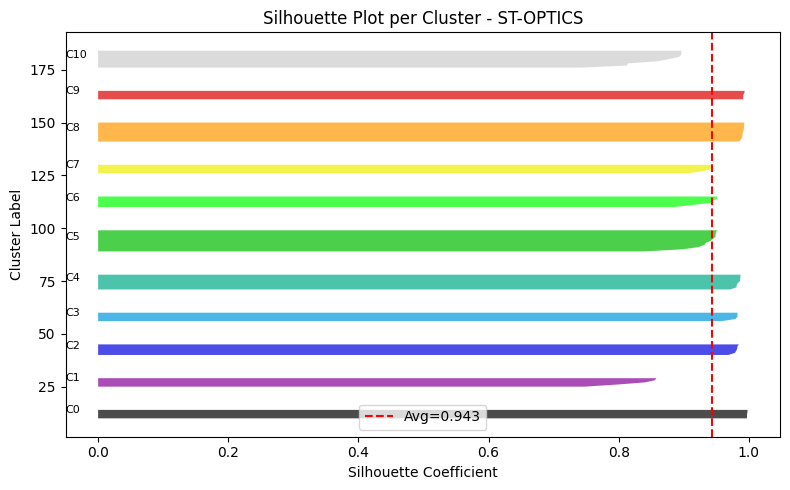

ST-OPTICS silhouette plot (English) saved!


In [40]:
#buat nampilin silhouette plot untuk mengevaluasi kualitas tiap klaster ST-OPTICS

from sklearn.metrics import silhouette_samples
import matplotlib.cm as cm

#ambil data yang udah ke-cluster aja (buang noise)
df_cl_optics = df_final_optics[df_final_optics['Cluster_OPTICS'] != -1]
X_eval_optics = np.column_stack([
    df_cl_optics[['Latitude', 'Longitude']].values,
    df_cl_optics[['Time_days']].values
])
labels_eval_optics = df_cl_optics['Cluster_OPTICS'].values

#hitung silhouette score per titik data
sample_silhouette_optics = silhouette_samples(X_eval_optics, labels_eval_optics)

#ambil daftar nomor klaster unik (urut), karena ST-OPTICS labelnya gak selalu 0..n berurutan rapi
unique_clusters = sorted(df_cl_optics['Cluster_OPTICS'].unique())
n_clusters_plot = len(unique_clusters)

fig, ax = plt.subplots(figsize=(8, 5))
y_lower = 10

#bikin warna berbeda untuk tiap klaster
colors_sil = cm.nipy_spectral(np.linspace(0, 1, n_clusters_plot))

#loop tiap klaster, urutkan nilai silhouette-nya, terus gambar sebagai "pita" horizontal
for idx, i in enumerate(unique_clusters):
    ith_sil = np.sort(sample_silhouette_optics[labels_eval_optics == i])
    y_upper = y_lower + len(ith_sil)
    ax.fill_betweenx(np.arange(y_lower, y_upper), 0, ith_sil,
                     facecolor=colors_sil[idx], alpha=0.7)
    ax.text(-0.05, y_lower + len(ith_sil)/2, f'C{i}', fontsize=8)
    y_lower = y_upper + 10

#garis vertikal merah menunjukkan rata-rata silhouette score ST-OPTICS (0.943, sesuai hasil di paper)
ax.axvline(x=0.943, color="red", linestyle="--", label='Avg=0.943')
ax.set_title('Silhouette Plot per Cluster - ST-OPTICS')
ax.set_xlabel('Silhouette Coefficient')
ax.set_ylabel('Cluster Label')
ax.legend()
plt.tight_layout()
plt.savefig('/drive/MyDrive/silhouette_plot_stoptics_en.png', dpi=300, bbox_inches='tight')
plt.show()
print("ST-OPTICS silhouette plot (English) saved!")

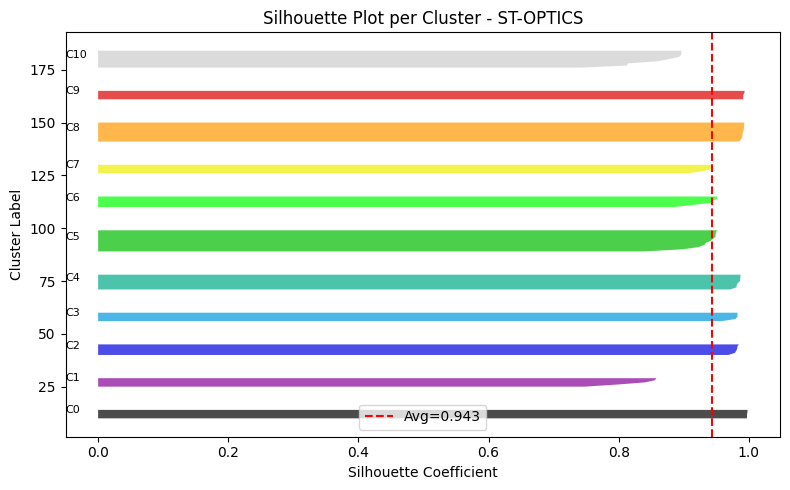

Silhouette plot ST-OPTICS tersimpan!


In [41]:
#buat nampilin silhouette plot untuk mengevaluasi kualitas tiap klaster ST-OPTICS
#(versi bahasa Indonesia)

from sklearn.metrics import silhouette_samples
import matplotlib.cm as cm

#ambil data yang udah ke-cluster aja (buang noise)
df_cl_optics = df_final_optics[df_final_optics['Cluster_OPTICS'] != -1]
X_eval_optics = np.column_stack([
    df_cl_optics[['Latitude', 'Longitude']].values,
    df_cl_optics[['Time_days']].values
])
labels_eval_optics = df_cl_optics['Cluster_OPTICS'].values

#hitung silhouette score per titik data
sample_silhouette_optics = silhouette_samples(X_eval_optics, labels_eval_optics)

#ambil daftar nomor klaster unik (urut), karena ST-OPTICS labelnya gak selalu 0..n berurutan rapi
unique_clusters = sorted(df_cl_optics['Cluster_OPTICS'].unique())
n_clusters_plot = len(unique_clusters)

fig, ax = plt.subplots(figsize=(8, 5))
y_lower = 10

#bikin warna berbeda untuk tiap klaster
colors_sil = cm.nipy_spectral(np.linspace(0, 1, n_clusters_plot))

#loop tiap klaster, urutkan nilai silhouette-nya, terus gambar sebagai "pita" horizontal
for idx, i in enumerate(unique_clusters):
    ith_sil = np.sort(sample_silhouette_optics[labels_eval_optics == i])
    y_upper = y_lower + len(ith_sil)
    ax.fill_betweenx(np.arange(y_lower, y_upper), 0, ith_sil,
                     facecolor=colors_sil[idx], alpha=0.7)
    ax.text(-0.05, y_lower + len(ith_sil)/2, f'C{i}', fontsize=8)
    y_lower = y_upper + 10

#garis vertikal merah menunjukkan rata-rata silhouette score ST-OPTICS (0.943, sesuai hasil di paper)
ax.axvline(x=0.943, color="red", linestyle="--", label='Avg=0.943')
ax.set_title('Silhouette Plot per Cluster - ST-OPTICS')
ax.set_xlabel('Silhouette Coefficient')
ax.set_ylabel('Cluster Label')
ax.legend()
plt.tight_layout()
plt.savefig('/drive/MyDrive/silhouette_plot_stoptics.png', dpi=300, bbox_inches='tight')
plt.show()
print("Silhouette plot ST-OPTICS tersimpan!")

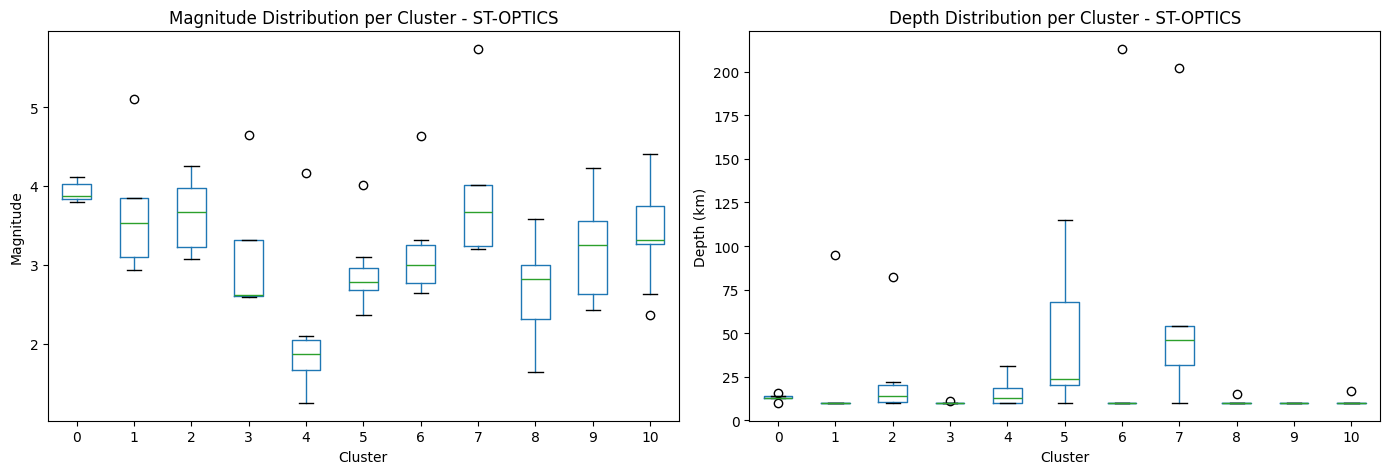

ST-OPTICS boxplot (English) saved!


In [42]:
#buat nampilin boxplot distribusi magnitudo dan kedalaman untuk tiap klaster ST-OPTICS

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

#ambil data yang udah ke-cluster aja (buang noise)
df_cl_optics = df_final_optics[df_final_optics['Cluster_OPTICS'] != -1].copy()

#subplot kiri: boxplot magnitudo per klaster
df_cl_optics.boxplot(column='Magnitude', by='Cluster_OPTICS', ax=axes[0], grid=False)
axes[0].set_xlabel('Cluster')
axes[0].set_ylabel('Magnitude')
plt.sca(axes[0])
plt.title('Magnitude Distribution per Cluster - ST-OPTICS')

#subplot kanan: boxplot kedalaman per klaster
df_cl_optics.boxplot(column='Depth (km)', by='Cluster_OPTICS', ax=axes[1], grid=False)
axes[1].set_xlabel('Cluster')
axes[1].set_ylabel('Depth (km)')
plt.sca(axes[1])
plt.title('Depth Distribution per Cluster - ST-OPTICS')

#hapus judul besar otomatis dari pandas boxplot biar gak dobel sama title masing-masing subplot
plt.suptitle('')
plt.tight_layout()
plt.savefig('/drive/MyDrive/boxplot_stoptics_en.png', dpi=300, bbox_inches='tight')
plt.show()
print("ST-OPTICS boxplot (English) saved!")

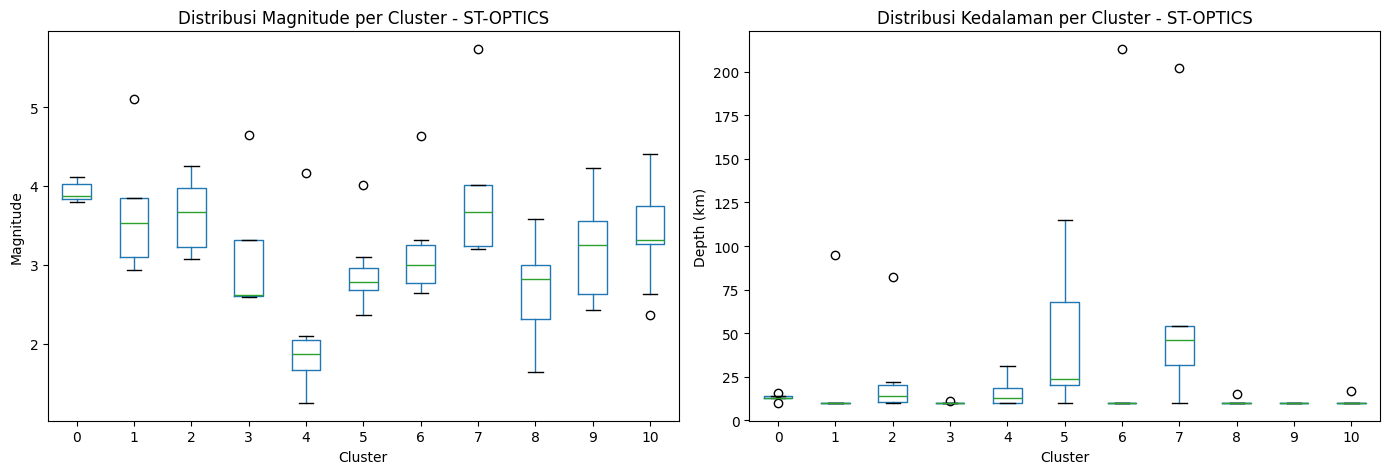

Boxplot ST-OPTICS tersimpan!


In [43]:
#buat nampilin boxplot distribusi magnitudo dan kedalaman untuk tiap klaster ST-OPTICS
#(versi bahasa Indonesia)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

#ambil data yang udah ke-cluster aja (buang noise)
df_cl_optics = df_final_optics[df_final_optics['Cluster_OPTICS'] != -1].copy()

#subplot kiri: boxplot magnitudo per klaster
df_cl_optics.boxplot(column='Magnitude', by='Cluster_OPTICS', ax=axes[0], grid=False)
axes[0].set_xlabel('Cluster')
axes[0].set_ylabel('Magnitude')
plt.sca(axes[0])
plt.title('Distribusi Magnitude per Cluster - ST-OPTICS')

#subplot kanan: boxplot kedalaman per klaster
df_cl_optics.boxplot(column='Depth (km)', by='Cluster_OPTICS', ax=axes[1], grid=False)
axes[1].set_xlabel('Cluster')
axes[1].set_ylabel('Depth (km)')
plt.sca(axes[1])
plt.title('Distribusi Kedalaman per Cluster - ST-OPTICS')

#hapus judul besar otomatis dari pandas boxplot biar gak dobel sama title masing-masing subplot
plt.suptitle('')
plt.tight_layout()
plt.savefig('/drive/MyDrive/boxplot_stoptics.png', dpi=300, bbox_inches='tight')
plt.show()
print("Boxplot ST-OPTICS tersimpan!")

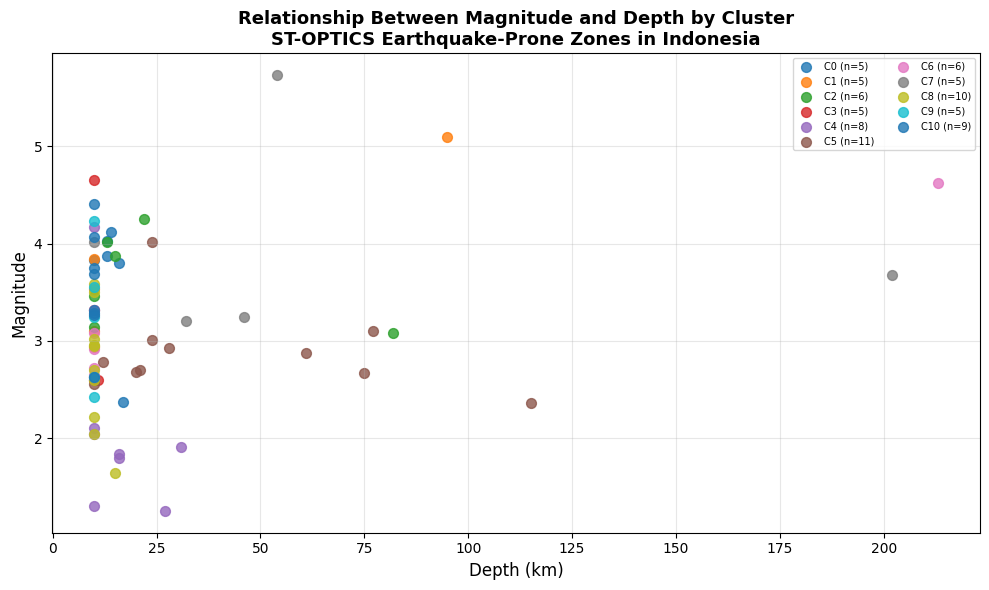

ST-OPTICS scatter plot (English) saved!


In [44]:
#buat nampilin scatter plot hubungan magnitudo dan kedalaman untuk tiap klaster ST-OPTICS

fig, ax = plt.subplots(figsize=(10, 6))

#scatter tiap klaster dengan warna beda, sumbu x = kedalaman, sumbu y = magnitudo
for i in sorted(df_cl_optics['Cluster_OPTICS'].unique()):
    cd = df_cl_optics[df_cl_optics['Cluster_OPTICS'] == i]
    ax.scatter(cd['Depth (km)'], cd['Magnitude'],
               c=colors[i % len(colors)], s=50, alpha=0.8,
               label=f'C{i} (n={len(cd)})')

ax.set_xlabel('Depth (km)', fontsize=12)
ax.set_ylabel('Magnitude', fontsize=12)
ax.set_title('Relationship Between Magnitude and Depth by Cluster\nST-OPTICS Earthquake-Prone Zones in Indonesia',
             fontsize=13, fontweight='bold')
ax.legend(loc='upper right', fontsize=7, ncol=2)
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('/drive/MyDrive/scatter_stoptics_en.png', dpi=300, bbox_inches='tight')
plt.show()
print("ST-OPTICS scatter plot (English) saved!")

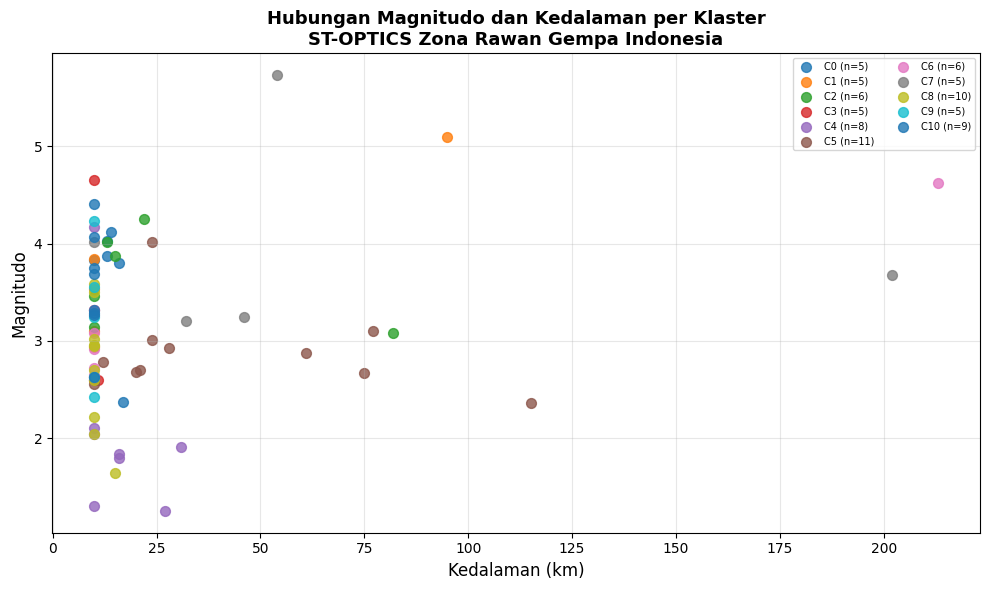

Scatter plot ST-OPTICS tersimpan!


In [45]:
#buat nampilin scatter plot hubungan magnitudo dan kedalaman untuk tiap klaster ST-OPTICS
#(versi bahasa Indonesia)

fig, ax = plt.subplots(figsize=(10, 6))

#scatter tiap klaster dengan warna beda, sumbu x = kedalaman, sumbu y = magnitudo
for i in sorted(df_cl_optics['Cluster_OPTICS'].unique()):
    cd = df_cl_optics[df_cl_optics['Cluster_OPTICS'] == i]
    ax.scatter(cd['Depth (km)'], cd['Magnitude'],
               c=colors[i % len(colors)], s=50, alpha=0.8,
               label=f'C{i} (n={len(cd)})')

ax.set_xlabel('Kedalaman (km)', fontsize=12)
ax.set_ylabel('Magnitudo', fontsize=12)
ax.set_title('Hubungan Magnitudo dan Kedalaman per Klaster\nST-OPTICS Zona Rawan Gempa Indonesia',
             fontsize=13, fontweight='bold')
ax.legend(loc='upper right', fontsize=7, ncol=2)
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('/drive/MyDrive/scatter_stoptics.png', dpi=300, bbox_inches='tight')
plt.show()
print("Scatter plot ST-OPTICS tersimpan!")

In [46]:
#buat nampilin tabel karakteristik lengkap tiap klaster ST-OPTICS
#meliputi jumlah anggota, statistik magnitudo, kedalaman, dan koordinat pusat

#group by nomor klaster ST-OPTICS (buang noise / -1), hitung statistik:
#jumlah anggota, rata-rata/maks magnitudo, rata-rata kedalaman, dan koordinat pusat (lat-lon)
cluster_stats_optics = df_final_optics[df_final_optics['Cluster_OPTICS'] != -1].groupby('Cluster_OPTICS').agg(
    Jumlah=('Magnitude', 'count'),
    Mag_mean=('Magnitude', 'mean'),
    Mag_max=('Magnitude', 'max'),
    Depth_mean=('Depth (km)', 'mean'),
    Lat_mean=('Latitude', 'mean'),
    Lon_mean=('Longitude', 'mean')
).round(2)

print("=== TABEL KARAKTERISTIK KLASTER ST-OPTICS ===")
print(cluster_stats_optics.to_string())

=== TABEL KARAKTERISTIK KLASTER ST-OPTICS ===
                Jumlah  Mag_mean  Mag_max  Depth_mean  Lat_mean  Lon_mean
Cluster_OPTICS                                                           
0                    5      3.93     4.12       13.20     -1.47    126.39
1                    5      3.70     5.10       27.00      0.19    127.03
2                    6      3.64     4.25       25.33      2.69    127.10
3                    5      3.16     4.65       10.20     -8.19    115.59
4                    8      2.05     4.17       16.25     -6.85    107.11
5                   11      2.88     4.02       42.45     -8.05    118.53
6                    6      3.22     4.63       43.83      1.71    127.95
7                    5      3.97     5.73       68.80     -6.95    105.33
8                   10      2.72     3.58       10.50     -5.79    104.77
9                    5      3.22     4.23       10.00      0.13    100.00
10                   9      3.42     4.41       10.78     -2.39   

In [47]:
#buat nampilin tabel hasil clustering ST-OPTICS lengkap dengan nama wilayah

#mapping nomor klaster ST-OPTICS ke nama wilayah (11 klaster)
wilayah_optics = {
    0: 'Maluku Utara',
    1: 'Maluku Utara (2)',
    2: 'Sulawesi Utara',
    3: 'Bali',
    4: 'Jawa Barat',
    5: 'Sumbawa/NTB',
    6: 'Halmahera',
    7: 'Selat Sunda',
    8: 'Lampung/Selat Sunda',
    9: 'Sumatera Barat',
    10: 'Papua Barat'
}

#tambahin kolom nama wilayah ke tabel cluster_stats_optics
cluster_stats_optics['Wilayah'] = cluster_stats_optics.index.map(wilayah_optics)

#tampilin tabel final yang siap dicopy ke paper
print("=== TABEL HASIL CLUSTER ST-OPTICS (untuk paper) ===")
print(cluster_stats_optics[['Wilayah', 'Jumlah', 'Mag_mean', 'Mag_max', 'Depth_mean', 'Lat_mean', 'Lon_mean']].to_string())

=== TABEL HASIL CLUSTER ST-OPTICS (untuk paper) ===
                            Wilayah  Jumlah  Mag_mean  Mag_max  Depth_mean  Lat_mean  Lon_mean
Cluster_OPTICS                                                                                
0                      Maluku Utara       5      3.93     4.12       13.20     -1.47    126.39
1                  Maluku Utara (2)       5      3.70     5.10       27.00      0.19    127.03
2                    Sulawesi Utara       6      3.64     4.25       25.33      2.69    127.10
3                              Bali       5      3.16     4.65       10.20     -8.19    115.59
4                        Jawa Barat       8      2.05     4.17       16.25     -6.85    107.11
5                       Sumbawa/NTB      11      2.88     4.02       42.45     -8.05    118.53
6                         Halmahera       6      3.22     4.63       43.83      1.71    127.95
7                       Selat Sunda       5      3.97     5.73       68.80     -6.95    105.3